In [1]:

# ============================================================
#  PREPARAÇÃO DOS DADOS - MCA PENSE 2024
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Arquivo de entrada
arquivo = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "08_PENSE2024_MCA_COORDENADAS.feather"
)

# Carregar dados
df_mca = pd.read_feather(arquivo)

print("=" * 65)
print("BASE DE COORDENADAS MCA - PENSE 2024")
print("=" * 65)

print(f"\nDimensões da base: {df_mca.shape}")
print(f"Quantidade de registros: {len(df_mca):,}")
print(f"Quantidade de colunas: {len(df_mca.columns)}")

# Identificar automaticamente colunas de coordenadas MCA
padrao_mca = re.compile(
    r"(dim|dimension|coord|axis|eixo|factor|component)",
    re.IGNORECASE
)

colunas_numericas = df_mca.select_dtypes(
    include=[np.number]
).columns.tolist()

colunas_mca = [
    c for c in colunas_numericas
    if padrao_mca.search(str(c))
]

# Caso os nomes não identifiquem as dimensões,
# utilizar todas as colunas numéricas, exceto identificadores.
if len(colunas_mca) < 2:

    colunas_mca = [
        c for c in colunas_numericas
        if not re.search(
            r"(^id$|^id_|_id$|codigo|código|identificador)",
            str(c),
            re.IGNORECASE
        )
    ]

print("\nColunas utilizadas na análise MCA:")
print(colunas_mca)

if len(colunas_mca) < 2:
    raise ValueError(
        "Não foram encontradas pelo menos duas colunas numéricas "
        "para realizar a clusterização."
    )

# Criar matriz de coordenadas
X = df_mca[colunas_mca].copy()

# Substituir valores infinitos por NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Remover registros com coordenadas ausentes
mascara_validos = X.notna().all(axis=1)

X = X.loc[mascara_validos].copy()

# Preservar índice dos registros originais
indices_validos = X.index

print("\nResultado da preparação:")
print(f"Registros válidos: {len(X):,}")
print(f"Registros removidos: {len(df_mca) - len(X):,}")
print(f"Dimensões MCA utilizadas: {X.shape[1]}")

# Converter para matriz NumPy
X_array = X.to_numpy(dtype=float)

# Identificar as duas primeiras dimensões para gráficos
dim1 = colunas_mca[0]
dim2 = colunas_mca[1]

print(f"\nGráficos utilizarão: {dim1} x {dim2}")


BASE DE COORDENADAS MCA - PENSE 2024

Dimensões da base: (118036, 31)
Quantidade de registros: 118,036
Quantidade de colunas: 31

Colunas utilizadas na análise MCA:
['indice_original', 'MCA_1', 'MCA_2', 'MCA_3', 'MCA_4', 'MCA_5', 'MCA_6', 'MCA_7', 'MCA_8', 'MCA_9', 'MCA_10', 'MCA_11', 'MCA_12', 'MCA_13', 'MCA_14', 'MCA_15', 'MCA_16', 'MCA_17', 'MCA_18', 'MCA_19', 'MCA_20', 'MCA_21', 'MCA_22', 'MCA_23', 'MCA_24', 'MCA_25', 'MCA_26', 'MCA_27', 'MCA_28', 'MCA_29', 'MCA_30']

Resultado da preparação:
Registros válidos: 118,036
Registros removidos: 0
Dimensões MCA utilizadas: 31

Gráficos utilizarão: indice_original x MCA_1


DBSCAN - ANÁLISE DE DENSIDADE

Calculando distâncias entre vizinhos...


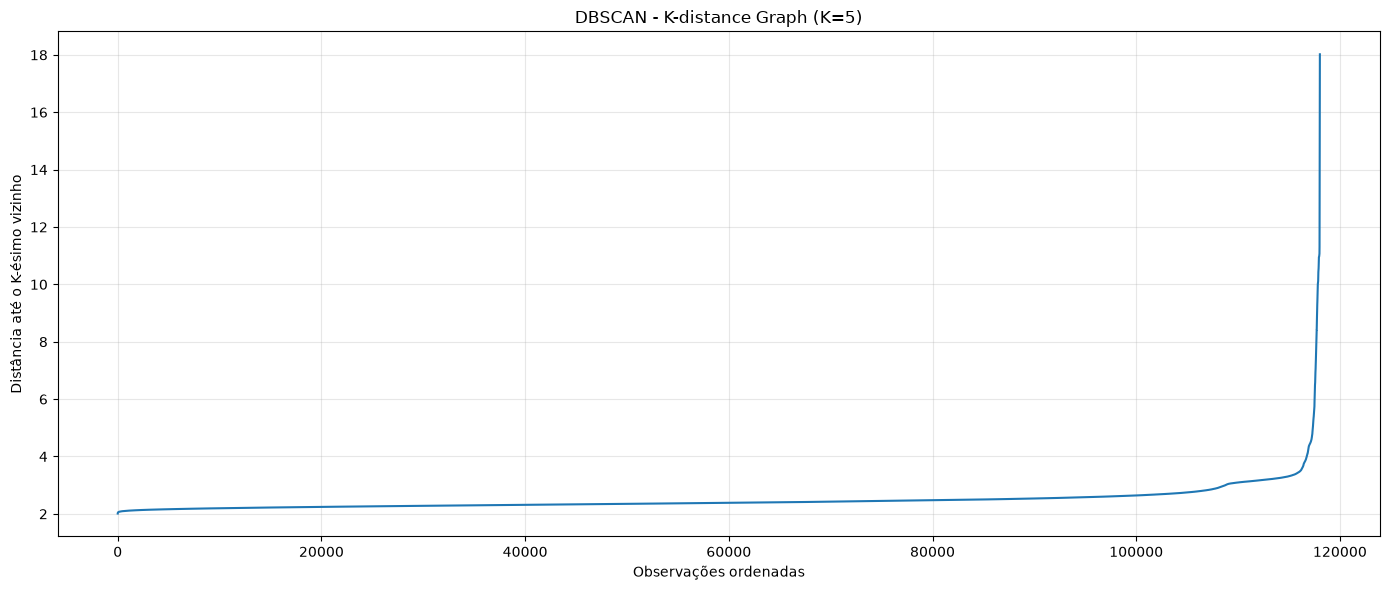


EPS inicial sugerido: 2.792641
MIN_SAMPLES: 5

RESULTADOS DBSCAN

EPS: 2.792641
MIN_SAMPLES: 5

Quantidade de clusters: 1632
Quantidade de ruídos: 2,786
Percentual de ruídos: 2.36%

Distribuição dos clusters:
Cluster_DBSCAN
-1       2786
 0         11
 1         18
 2         32
 3         10
         ... 
 1627      72
 1628      11
 1629     152
 1630      43
 1631      23
Name: count, Length: 1633, dtype: int64

Silhouette Score (sem ruídos): 0.2597


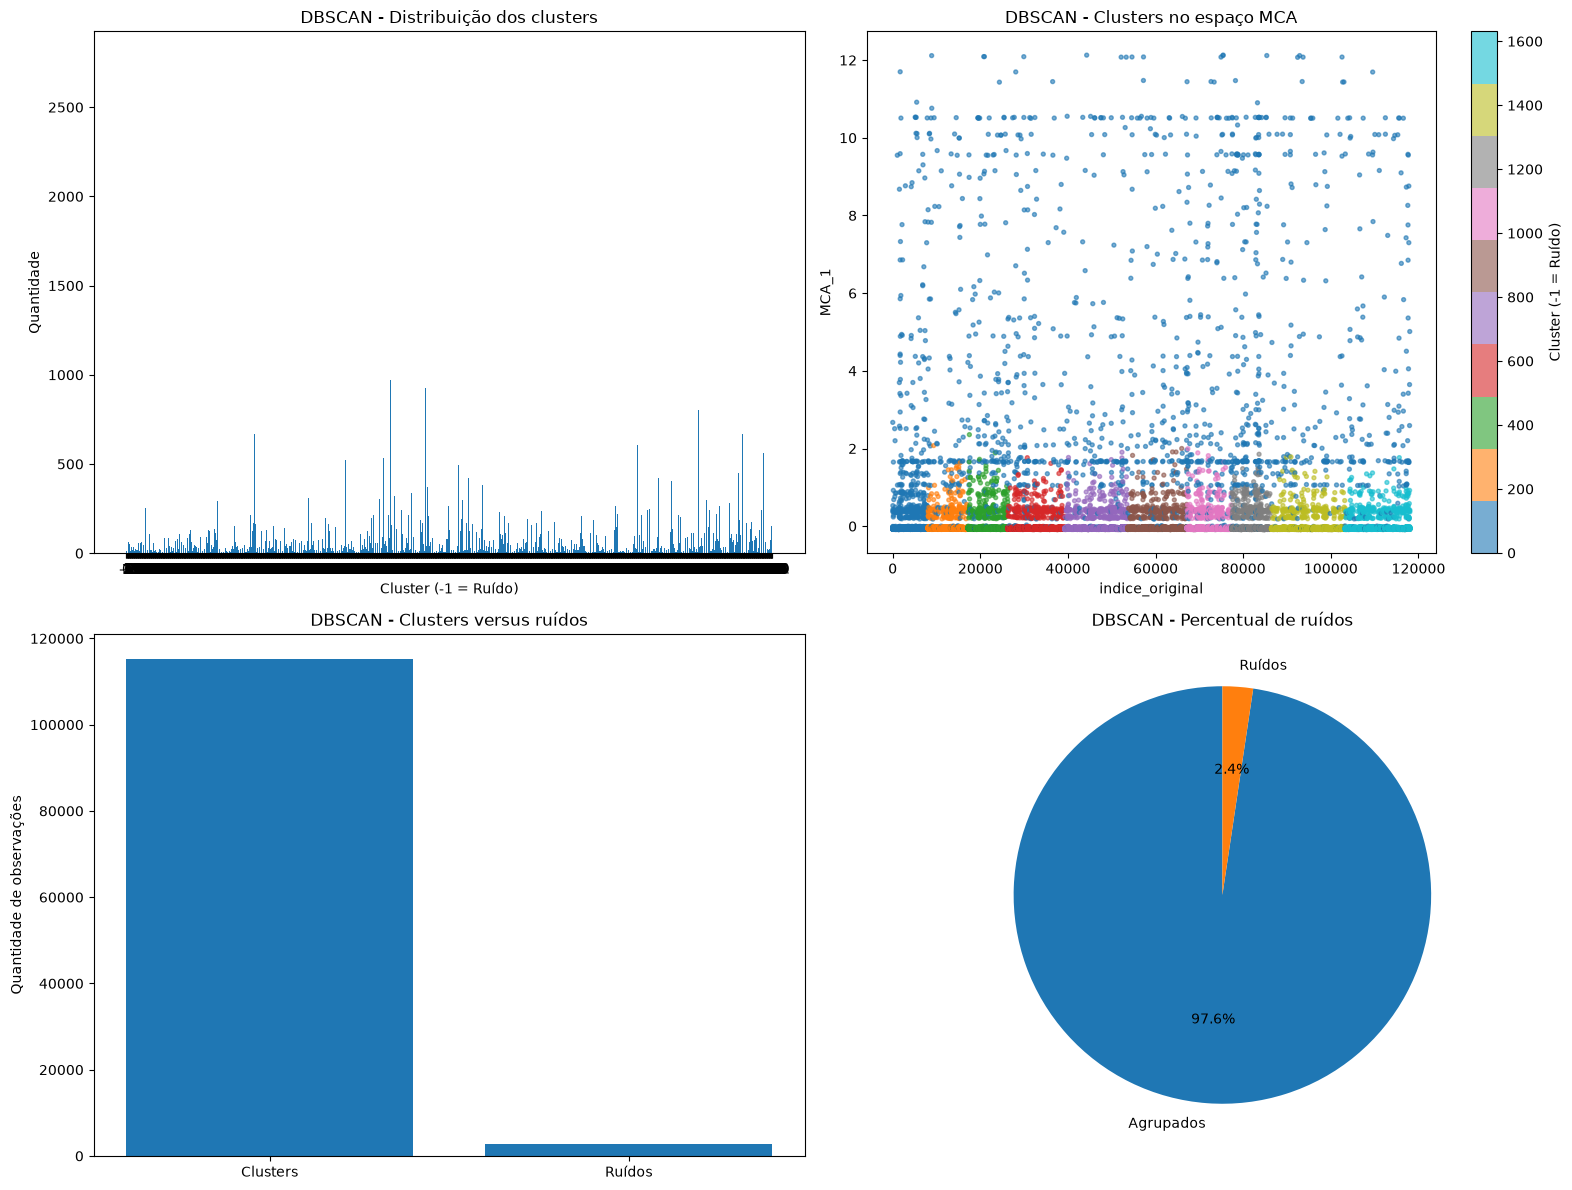


Médias das coordenadas MCA por cluster:


,indice_original,MCA_1,MCA_2,MCA_3,MCA_4,MCA_5,MCA_6,MCA_7,MCA_8,MCA_9,...,MCA_21,MCA_22,MCA_23,MCA_24,MCA_25,MCA_26,MCA_27,MCA_28,MCA_29,MCA_30
Cluster_DBSCAN,,,,,,,,,,,,,,,,,,,,,
0,5.0,-0.0149,0.3560,0.0406,0.0183,0.0401,-0.0239,-0.0177,0.0011,-0.0254,...,-0.0089,-0.1066,0.0197,-0.0263,0.0733,0.0239,-0.1168,0.0459,-0.0653,0.0223
1,20.5,-0.0305,0.0890,0.1653,0.0340,-0.0518,-0.0974,0.0157,-0.0643,0.0384,...,-0.0704,-0.0995,0.0369,0.0035,0.0007,0.0309,-0.0458,0.0103,0.0257,-0.0156
2,45.5,-0.0537,-0.1692,-0.0430,0.0403,-0.0048,-0.0091,-0.0158,-0.1254,-0.0017,...,-0.0197,-0.0958,0.0215,-0.0001,0.0380,-0.0218,-0.0313,-0.0187,0.0042,-0.0316
3,67.5,-0.0706,-0.2203,-0.1217,-0.0019,0.0108,0.0252,-0.0176,-0.1422,0.0343,...,-0.0414,-0.1216,0.0489,0.0467,0.0044,-0.0463,-0.0476,0.0400,-0.0410,-0.0112
4,79.0,-0.0149,-0.0430,0.1286,-0.0216,0.0896,0.0179,-0.0315,-0.0558,-0.0664,...,-0.0500,-0.0818,-0.0396,-0.0744,0.0282,0.0129,-0.0125,-0.0447,0.0117,-0.0522
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1627,117757.5,-0.0631,-0.0142,0.0001,0.0312,-0.0172,-0.0411,0.0018,0.0406,-0.0996,...,0.0642,-0.0352,0.0011,0.0121,-0.0406,-0.0092,-0.0349,0.0630,0.0065,-0.0208
1628,117805.0,0.0979,0.0378,-0.0943,-0.1141,-0.0497,0.0067,0.0354,0.0769,-0.0455,...,0.2033,-0.1155,0.0103,-0.0652,-0.0829,0.1020,-0.2077,0.1186,-0.0448,0.0696
1629,117887.5,-0.0462,0.0765,0.3643,0.1111,-0.0626,-0.1607,0.0086,-0.0418,-0.1389,...,0.0376,0.0095,-0.0463,-0.0124,-0.0384,0.0000,0.0081,0.0075,0.0018,-0.0039



Análise concluída.


In [2]:

# ============================================================
#  DBSCAN - DENSITY BASED SPATIAL CLUSTERING
#  PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

# ============================================================
# PARÂMETROS
# ============================================================

MIN_SAMPLES = 5

# Número de vizinhos para calcular K-distance
K_DIST = MIN_SAMPLES

# ============================================================
# CALCULAR K-DISTANCE
# ============================================================

print("=" * 65)
print("DBSCAN - ANÁLISE DE DENSIDADE")
print("=" * 65)

print("\nCalculando distâncias entre vizinhos...")

neighbors = NearestNeighbors(
    n_neighbors=K_DIST,
    metric="euclidean",
    n_jobs=-1
)

neighbors.fit(X_array)

distancias, indices = neighbors.kneighbors(X_array)

# Distância até o K-ésimo vizinho
k_distances = np.sort(distancias[:, -1])

# Gráfico K-distance
plt.figure(figsize=(14, 6))

plt.plot(k_distances)

plt.title(
    f"DBSCAN - K-distance Graph (K={K_DIST})"
)

plt.xlabel("Observações ordenadas")
plt.ylabel("Distância até o K-ésimo vizinho")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# DEFINIÇÃO INICIAL DE EPS
# ============================================================

# Heurística inicial: percentil 90 da distância K
# IMPORTANTE: ajuste EPS após observar o gráfico K-distance.

EPS = float(np.percentile(k_distances, 90))

print(f"\nEPS inicial sugerido: {EPS:.6f}")
print(f"MIN_SAMPLES: {MIN_SAMPLES}")

# Você pode substituir o valor acima após observar o gráfico.
# Exemplo:
# EPS = 0.35

# ============================================================
# EXECUTAR DBSCAN
# ============================================================

modelo_dbscan = DBSCAN(
    eps=EPS,
    min_samples=MIN_SAMPLES,
    metric="euclidean",
    n_jobs=-1
)

clusters_dbscan = modelo_dbscan.fit_predict(X_array)

# Criar resultados
df_resultado_dbscan = df_mca.loc[
    indices_validos
].copy()

df_resultado_dbscan["Cluster_DBSCAN"] = clusters_dbscan

# ============================================================
# IDENTIFICAR CLUSTERS E RUÍDOS
# ============================================================

quantidade_ruido = np.sum(clusters_dbscan == -1)

clusters_identificados = sorted(
    set(clusters_dbscan) - {-1}
)

quantidade_clusters = len(clusters_identificados)

percentual_ruido = (
    quantidade_ruido / len(clusters_dbscan)
) * 100

print("\n" + "=" * 65)
print("RESULTADOS DBSCAN")
print("=" * 65)

print(f"\nEPS: {EPS:.6f}")
print(f"MIN_SAMPLES: {MIN_SAMPLES}")

print(f"\nQuantidade de clusters: {quantidade_clusters}")

print(f"Quantidade de ruídos: {quantidade_ruido:,}")

print(f"Percentual de ruídos: {percentual_ruido:.2f}%")

print("\nDistribuição dos clusters:")

print(
    df_resultado_dbscan["Cluster_DBSCAN"]
    .value_counts()
    .sort_index()
)

# ============================================================
# SILHOUETTE SCORE
# ============================================================

# O ruído (-1) não será considerado na avaliação.

mascara_clusters = clusters_dbscan != -1

X_sem_ruido = X_array[mascara_clusters]

labels_sem_ruido = clusters_dbscan[mascara_clusters]

if (
    len(np.unique(labels_sem_ruido)) >= 2
    and len(X_sem_ruido) > 2
):

    # Amostra para reduzir custo computacional
    if len(X_sem_ruido) > 10000:

        rng = np.random.RandomState(42)

        amostra = rng.choice(
            len(X_sem_ruido),
            10000,
            replace=False
        )

        silhouette_dbscan = silhouette_score(
            X_sem_ruido[amostra],
            labels_sem_ruido[amostra]
        )

    else:

        silhouette_dbscan = silhouette_score(
            X_sem_ruido,
            labels_sem_ruido
        )

else:

    silhouette_dbscan = np.nan

print(
    f"\nSilhouette Score (sem ruídos): "
    f"{silhouette_dbscan:.4f}"
)

# ============================================================
# GRÁFICOS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1 - Distribuição dos clusters
distribuicao = (
    df_resultado_dbscan["Cluster_DBSCAN"]
    .value_counts()
    .sort_index()
)

axes[0, 0].bar(
    distribuicao.index.astype(str),
    distribuicao.values
)

axes[0, 0].set_title("DBSCAN - Distribuição dos clusters")
axes[0, 0].set_xlabel("Cluster (-1 = Ruído)")
axes[0, 0].set_ylabel("Quantidade")

# 2 - Visualização dos clusters MCA
scatter = axes[0, 1].scatter(
    X_array[:, 0],
    X_array[:, 1],
    c=clusters_dbscan,
    cmap="tab10",
    s=8,
    alpha=0.6
)

axes[0, 1].set_title("DBSCAN - Clusters no espaço MCA")
axes[0, 1].set_xlabel(dim1)
axes[0, 1].set_ylabel(dim2)

plt.colorbar(scatter, ax=axes[0, 1], label="Cluster (-1 = Ruído)")

# 3 - Separação entre ruído e observações agrupadas
tipos = [
    "Clusters",
    "Ruídos"
]

valores = [
    len(clusters_dbscan) - quantidade_ruido,
    quantidade_ruido
]

axes[1, 0].bar(tipos, valores)

axes[1, 0].set_title("DBSCAN - Clusters versus ruídos")
axes[1, 0].set_ylabel("Quantidade de observações")

# 4 - Percentual de ruído
axes[1, 1].pie(
    [
        100 - percentual_ruido,
        percentual_ruido
    ],
    labels=["Agrupados", "Ruídos"],
    autopct="%1.1f%%",
    startangle=90
)

axes[1, 1].set_title("DBSCAN - Percentual de ruídos")

plt.tight_layout()
plt.show()

# ============================================================
# ANÁLISE DOS CLUSTERS
# ============================================================

print("\nMédias das coordenadas MCA por cluster:")

display(
    df_resultado_dbscan[
        df_resultado_dbscan["Cluster_DBSCAN"] != -1
    ]
    .groupby("Cluster_DBSCAN")[colunas_mca]
    .mean()
    .round(4)
)

print("\nAnálise concluída.")



Não foi possível calcular DBCV: Invalid shape in axis 0: 0.

AVALIAÇÃO AMPLIADA DBSCAN - PENSE 2024

MÉTRICAS GERAIS


,Metrica,Resultado
0,Quantidade de clusters,1.632000e+03
1,Quantidade de observações agrupadas,1.152500e+05
2,Quantidade de ruídos,2.786000e+03
3,Noise Ratio (%),2.360300e+00
4,Core Points Ratio (%),8.999880e+01
5,Border Points Ratio (%),7.640900e+00
6,Silhouette Score (sem ruídos),2.597000e-01
7,Calinski-Harabasz (sem ruídos),1.079573e+06
8,Davies-Bouldin (sem ruídos),4.671000e-01
9,DBCV,NaN



DISTRIBUIÇÃO DOS CLUSTERS


,Cluster,Quantidade,Percentual_Base_Total
0,0,11,0.01
1,1,18,0.02
2,2,32,0.03
3,3,10,0.01
4,4,11,0.01
...,...,...,...
1627,1627,72,0.06
1628,1628,11,0.01
1629,1629,152,0.13
1630,1630,43,0.04



SILHOUETTE POR CLUSTER


,Media,Mediana,Desvio_Padrao,Minimo,Maximo,Observacoes
Cluster,,,,,,
2,0.8038,0.8172,0.0603,0.7379,0.8563,3
3,0.0000,0.0000,NaN,0.0000,0.0000,1
5,-0.0297,0.0930,0.4729,-0.7608,0.4450,10
6,0.7699,0.7699,0.0361,0.7444,0.7954,2
7,-0.0318,0.1068,0.4971,-0.8839,0.5459,24
...,...,...,...,...,...,...
1627,0.4487,0.5558,0.2899,-0.1700,0.6656,7
1628,0.8184,0.8184,0.0226,0.8025,0.8344,2
1629,-0.0195,-0.0103,0.4386,-0.6735,0.5253,19


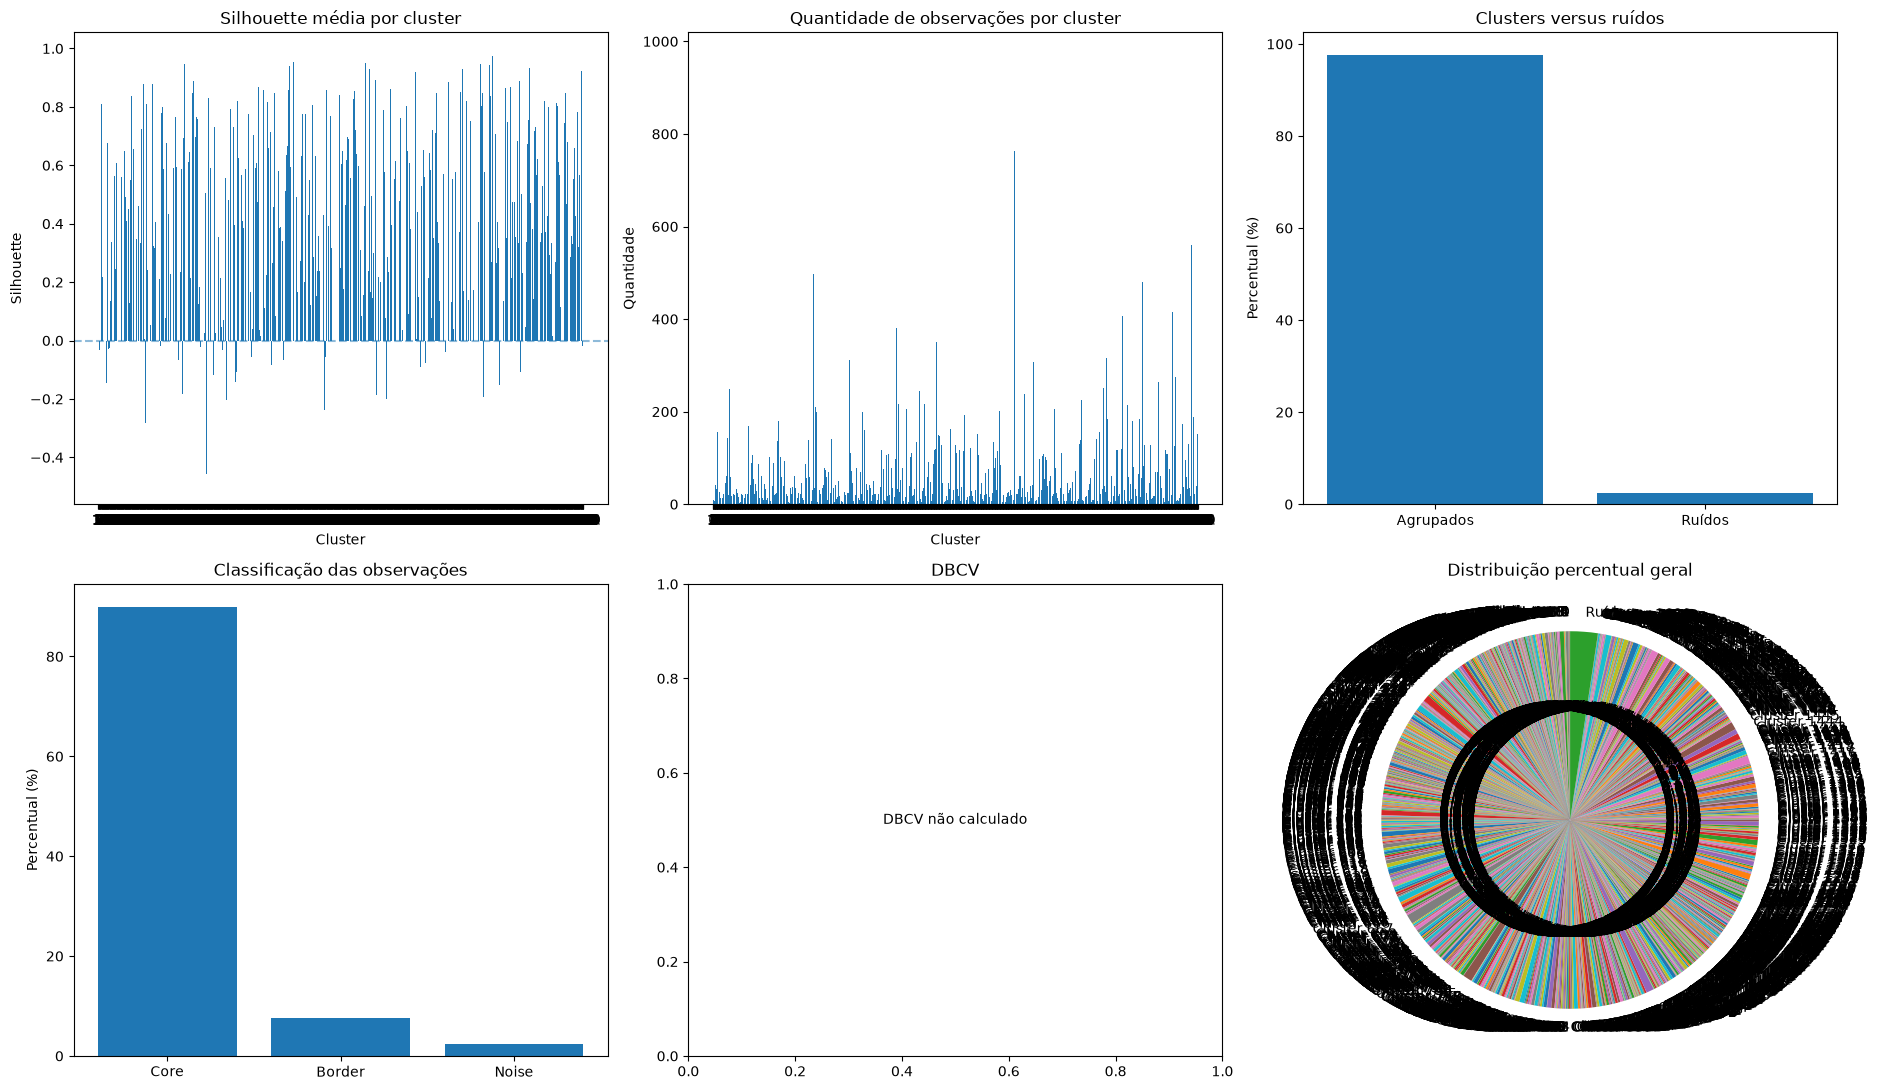


Avaliação ampliada DBSCAN concluída.


In [3]:

# ============================================================
# 9. MÉTRICAS ADICIONAIS DE AVALIAÇÃO DO DBSCAN
# PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
    silhouette_samples,
    adjusted_rand_score
)

from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 9.1. IDENTIFICAR CLUSTERS E RUÍDOS
# ------------------------------------------------------------

labels_dbscan = clusters_dbscan

clusters_validos_dbscan = sorted(
    set(labels_dbscan) - {-1}
)

K_DBSCAN = len(clusters_validos_dbscan)

mascara_sem_ruido = labels_dbscan != -1

X_sem_ruido = X_array[mascara_sem_ruido]

labels_sem_ruido = labels_dbscan[mascara_sem_ruido]

quantidade_total = len(labels_dbscan)

quantidade_ruido = np.sum(~mascara_sem_ruido)

quantidade_agrupados = np.sum(mascara_sem_ruido)

percentual_ruido = (
    quantidade_ruido / quantidade_total
) * 100

percentual_agrupados = (
    quantidade_agrupados / quantidade_total
) * 100

# ------------------------------------------------------------
# 9.2. PREPARAR AMOSTRA PARA MÉTRICAS
# ------------------------------------------------------------

MAX_AMOSTRA_DBSCAN = 10000

if len(X_sem_ruido) > MAX_AMOSTRA_DBSCAN:

    rng = np.random.RandomState(42)

    indices_amostra = rng.choice(
        len(X_sem_ruido),
        MAX_AMOSTRA_DBSCAN,
        replace=False
    )

    X_avaliacao = X_sem_ruido[indices_amostra]

    labels_avaliacao = labels_sem_ruido[indices_amostra]

else:

    X_avaliacao = X_sem_ruido

    labels_avaliacao = labels_sem_ruido

# ------------------------------------------------------------
# 9.3. CALINSKI-HARABASZ E DAVIES-BOULDIN
# ------------------------------------------------------------

if (
    len(np.unique(labels_avaliacao)) >= 2
    and len(np.unique(labels_avaliacao)) < len(labels_avaliacao)
):

    ch_score_dbscan = calinski_harabasz_score(
        X_avaliacao,
        labels_avaliacao
    )

    db_score_dbscan = davies_bouldin_score(
        X_avaliacao,
        labels_avaliacao
    )

else:

    ch_score_dbscan = np.nan

    db_score_dbscan = np.nan

# ------------------------------------------------------------
# 9.4. SILHOUETTE POR CLUSTER
# ------------------------------------------------------------

if (
    len(np.unique(labels_avaliacao)) >= 2
    and len(np.unique(labels_avaliacao)) < len(labels_avaliacao)
):

    silhouette_individual_dbscan = silhouette_samples(
        X_avaliacao,
        labels_avaliacao
    )

    df_silhouette_dbscan = pd.DataFrame({
        "Cluster": labels_avaliacao,
        "Silhouette": silhouette_individual_dbscan
    })

    silhouette_clusters_dbscan = (
        df_silhouette_dbscan
        .groupby("Cluster")["Silhouette"]
        .agg(["mean", "median", "std", "min", "max", "count"])
        .round(4)
    )

    silhouette_clusters_dbscan.columns = [
        "Media",
        "Mediana",
        "Desvio_Padrao",
        "Minimo",
        "Maximo",
        "Observacoes"
    ]

    silhouette_medio_dbscan = silhouette_score(
        X_avaliacao,
        labels_avaliacao
    )

else:

    silhouette_clusters_dbscan = pd.DataFrame()

    silhouette_medio_dbscan = np.nan

# ------------------------------------------------------------
# 9.5. DBCV - DENSITY-BASED CLUSTERING VALIDATION
# ------------------------------------------------------------

# DBCV é uma métrica especialmente interessante para DBSCAN.
# Requer o pacote hdbscan.

dbcv_score = np.nan
dbcv_scores_clusters = None

try:

    from hdbscan.validity import validity_index

    # Utilizar a amostra de avaliação sem ruídos
    # para reduzir o custo computacional.

    if (
        len(np.unique(labels_avaliacao)) >= 2
        and len(np.unique(labels_avaliacao)) < len(labels_avaliacao)
    ):

        dbcv_score, dbcv_scores_clusters = validity_index(
            X_avaliacao,
            labels_avaliacao,
            metric="euclidean",
            per_cluster_scores=True
        )

except ImportError:

    print(
        "\nPacote hdbscan não instalado. "
        "Para calcular DBCV, execute no Jupyter:\n"
        "%pip install hdbscan"
    )

except Exception as erro:

    print("\nNão foi possível calcular DBCV:", erro)

# ------------------------------------------------------------
# 9.6. CORE POINTS RATIO
# ------------------------------------------------------------

# Pontos centrais identificados pelo DBSCAN

core_indices = modelo_dbscan.core_sample_indices_

quantidade_core = len(core_indices)

percentual_core = (
    quantidade_core / quantidade_total
) * 100

# Pontos não centrais pertencentes aos clusters
quantidade_border = (
    quantidade_agrupados - quantidade_core
)

percentual_border = (
    quantidade_border / quantidade_total
) * 100

# ------------------------------------------------------------
# 9.7. DISTRIBUIÇÃO E EQUILÍBRIO DOS CLUSTERS
# ------------------------------------------------------------

tamanhos_dbscan = np.array([
    np.sum(labels_dbscan == k)
    for k in clusters_validos_dbscan
])

percentuais_dbscan = (
    tamanhos_dbscan / quantidade_total
) * 100

df_balance_dbscan = pd.DataFrame({
    "Cluster": clusters_validos_dbscan,
    "Quantidade": tamanhos_dbscan,
    "Percentual_Base_Total": percentuais_dbscan
})

if K_DBSCAN > 0:

    proporcoes_clusters = (
        tamanhos_dbscan / tamanhos_dbscan.sum()
    )

    entropia_balance_dbscan = -np.sum(
        proporcoes_clusters * np.log(proporcoes_clusters)
    )

    entropia_balance_normalizada = (
        entropia_balance_dbscan / np.log(K_DBSCAN)
        if K_DBSCAN > 1 else np.nan
    )

    razao_balance_dbscan = (
        tamanhos_dbscan.max() / tamanhos_dbscan.min()
    )

else:

    entropia_balance_normalizada = np.nan

    razao_balance_dbscan = np.nan

# ------------------------------------------------------------
# 9.8. RESULTADOS CONSOLIDADOS
# ------------------------------------------------------------

resultados_metricas_dbscan = pd.DataFrame({

    "Metrica": [
        "Quantidade de clusters",
        "Quantidade de observações agrupadas",
        "Quantidade de ruídos",
        "Noise Ratio (%)",
        "Core Points Ratio (%)",
        "Border Points Ratio (%)",
        "Silhouette Score (sem ruídos)",
        "Calinski-Harabasz (sem ruídos)",
        "Davies-Bouldin (sem ruídos)",
        "DBCV",
        "Cluster Balance (entropia)",
        "Razão maior/menor cluster"
    ],

    "Resultado": [
        K_DBSCAN,
        quantidade_agrupados,
        quantidade_ruido,
        percentual_ruido,
        percentual_core,
        percentual_border,
        silhouette_medio_dbscan,
        ch_score_dbscan,
        db_score_dbscan,
        dbcv_score,
        entropia_balance_normalizada,
        razao_balance_dbscan
    ]
})

print("\n" + "=" * 75)
print("AVALIAÇÃO AMPLIADA DBSCAN - PENSE 2024")
print("=" * 75)

print("\nMÉTRICAS GERAIS")

display(resultados_metricas_dbscan.round(4))

print("\nDISTRIBUIÇÃO DOS CLUSTERS")

display(df_balance_dbscan.round(2))

print("\nSILHOUETTE POR CLUSTER")

display(silhouette_clusters_dbscan)

if dbcv_scores_clusters is not None:

    print("\nDBCV POR CLUSTER")

    display(
        pd.DataFrame({
            "Cluster": clusters_validos_dbscan,
            "DBCV": dbcv_scores_clusters
        }).round(4)
    )

# ------------------------------------------------------------
# 9.9. GRÁFICOS DAS MÉTRICAS
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# Gráfico 1 - Silhouette por cluster

if not silhouette_clusters_dbscan.empty:

    axes[0, 0].bar(
        silhouette_clusters_dbscan.index.astype(str),
        silhouette_clusters_dbscan["Media"]
    )

    axes[0, 0].axhline(
        0,
        linestyle="--",
        alpha=0.5
    )

    axes[0, 0].set_title("Silhouette média por cluster")
    axes[0, 0].set_xlabel("Cluster")
    axes[0, 0].set_ylabel("Silhouette")

else:

    axes[0, 0].text(
        0.5, 0.5,
        "Não calculável",
        ha="center",
        va="center"
    )

    axes[0, 0].set_title("Silhouette por cluster")

# Gráfico 2 - Distribuição dos clusters

axes[0, 1].bar(
    df_balance_dbscan["Cluster"].astype(str),
    df_balance_dbscan["Quantidade"]
)

axes[0, 1].set_title("Quantidade de observações por cluster")
axes[0, 1].set_xlabel("Cluster")
axes[0, 1].set_ylabel("Quantidade")

# Gráfico 3 - Clusters versus ruídos

axes[0, 2].bar(
    ["Agrupados", "Ruídos"],
    [percentual_agrupados, percentual_ruido]
)

axes[0, 2].set_title("Clusters versus ruídos")
axes[0, 2].set_ylabel("Percentual (%)")

# Gráfico 4 - Core, Border e Noise

axes[1, 0].bar(
    ["Core", "Border", "Noise"],
    [
        percentual_core,
        percentual_border,
        percentual_ruido
    ]
)

axes[1, 0].set_title("Classificação das observações")
axes[1, 0].set_ylabel("Percentual (%)")

# Gráfico 5 - DBCV

if not np.isnan(dbcv_score):

    axes[1, 1].bar(
        ["DBCV"],
        [dbcv_score]
    )

    axes[1, 1].axhline(
        0,
        linestyle="--",
        alpha=0.5
    )

    axes[1, 1].set_title("Density-Based Clustering Validation")
    axes[1, 1].set_ylabel("DBCV")

else:

    axes[1, 1].text(
        0.5, 0.5,
        "DBCV não calculado",
        ha="center",
        va="center"
    )

    axes[1, 1].set_title("DBCV")

# Gráfico 6 - Distribuição percentual dos clusters

axes[1, 2].pie(
    list(percentuais_dbscan) + [percentual_ruido],
    labels=[
        f"Cluster {k}" for k in clusters_validos_dbscan
    ] + ["Ruídos"],
    autopct="%1.1f%%",
    startangle=90
)

axes[1, 2].set_title("Distribuição percentual geral")

plt.tight_layout()
plt.show()

print("\nAvaliação ampliada DBSCAN concluída.")



ESTABILIDADE DBSCAN - ANÁLISE DE SENSIBILIDADE EPS


,Multiplicador_EPS,EPS,Quantidade_Clusters,Percentual_Ruido,ARI
0,0.8,2.2341,1,99.95,0.6663
1,0.9,2.5134,2,99.90,1.0000
2,1.0,2.7926,2,99.90,1.0000
3,1.1,3.0719,2,99.90,1.0000
4,1.2,3.3512,2,99.89,0.9523


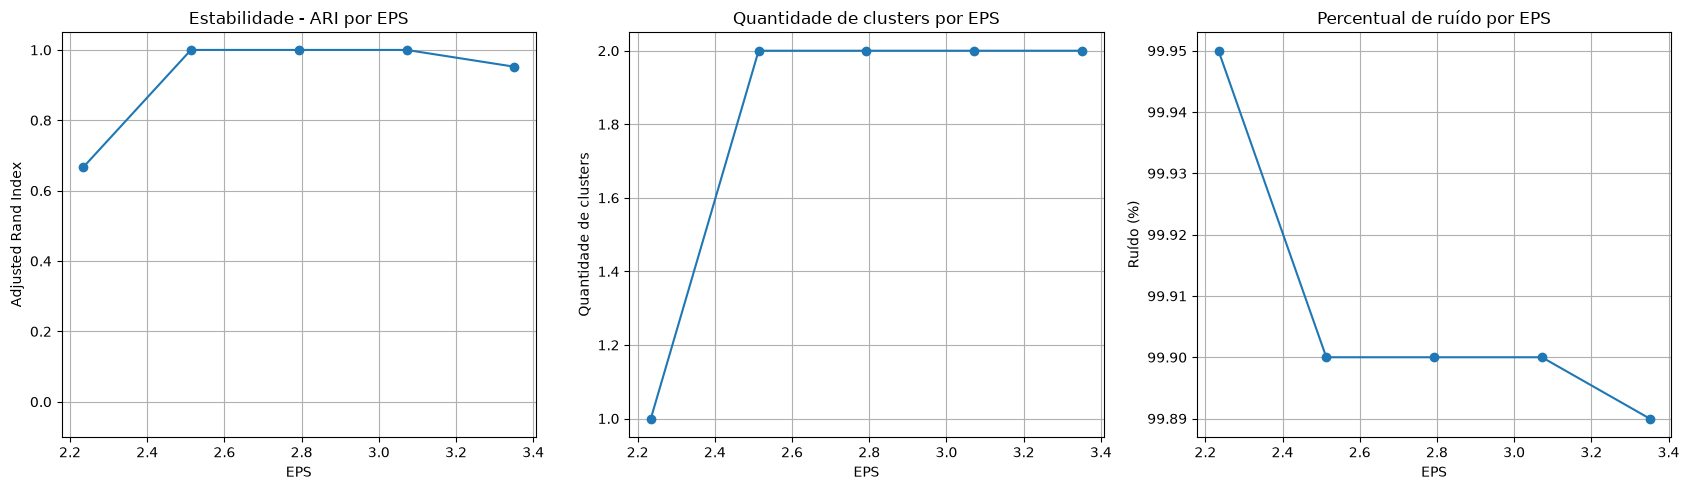


Análise de estabilidade DBSCAN concluída.


In [4]:

# ============================================================
# 10. ESTABILIDADE DO DBSCAN
# ANÁLISE DE SENSIBILIDADE - EPS
# ============================================================

from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score

# ------------------------------------------------------------
# 10.1. PARÂMETROS
# ------------------------------------------------------------

MULTIPLICADORES_EPS = [
    0.80,
    0.90,
    1.00,
    1.10,
    1.20
]

MAX_AMOSTRA_ESTABILIDADE = 10000

# Utilizar amostra fixa para reduzir custo computacional

rng = np.random.RandomState(42)

if len(X_array) > MAX_AMOSTRA_ESTABILIDADE:

    indices_estabilidade = rng.choice(
        len(X_array),
        MAX_AMOSTRA_ESTABILIDADE,
        replace=False
    )

else:

    indices_estabilidade = np.arange(len(X_array))

X_estabilidade = X_array[indices_estabilidade]

# ------------------------------------------------------------
# 10.2. MODELO DE REFERÊNCIA
# ------------------------------------------------------------

modelo_referencia = DBSCAN(
    eps=EPS,
    min_samples=MIN_SAMPLES,
    metric="euclidean",
    n_jobs=-1
)

labels_referencia = modelo_referencia.fit_predict(
    X_estabilidade
)

# ------------------------------------------------------------
# 10.3. TESTAR DIFERENTES VALORES DE EPS
# ------------------------------------------------------------

resultados_estabilidade_dbscan = []

for multiplicador in MULTIPLICADORES_EPS:

    eps_teste = EPS * multiplicador

    modelo_teste = DBSCAN(
        eps=eps_teste,
        min_samples=MIN_SAMPLES,
        metric="euclidean",
        n_jobs=-1
    )

    labels_teste = modelo_teste.fit_predict(
        X_estabilidade
    )

    # ARI incluindo ruídos (-1)
    ari = adjusted_rand_score(
        labels_referencia,
        labels_teste
    )

    clusters_teste = (
        set(labels_teste) - {-1}
    )

    ruido_teste = np.sum(labels_teste == -1)

    percentual_ruido_teste = (
        ruido_teste / len(labels_teste)
    ) * 100

    resultados_estabilidade_dbscan.append({

        "Multiplicador_EPS": multiplicador,

        "EPS": eps_teste,

        "Quantidade_Clusters": len(clusters_teste),

        "Percentual_Ruido": percentual_ruido_teste,

        "ARI": ari
    })

# ------------------------------------------------------------
# 10.4. RESULTADOS
# ------------------------------------------------------------

df_estabilidade_dbscan = pd.DataFrame(
    resultados_estabilidade_dbscan
)

print("\n" + "=" * 75)
print("ESTABILIDADE DBSCAN - ANÁLISE DE SENSIBILIDADE EPS")
print("=" * 75)

display(df_estabilidade_dbscan.round(4))

# ------------------------------------------------------------
# 10.5. GRÁFICOS
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Gráfico 1 - ARI

axes[0].plot(
    df_estabilidade_dbscan["EPS"],
    df_estabilidade_dbscan["ARI"],
    marker="o"
)

axes[0].set_title("Estabilidade - ARI por EPS")
axes[0].set_xlabel("EPS")
axes[0].set_ylabel("Adjusted Rand Index")
axes[0].set_ylim(-0.1, 1.05)
axes[0].grid(True)

# Gráfico 2 - Quantidade de clusters

axes[1].plot(
    df_estabilidade_dbscan["EPS"],
    df_estabilidade_dbscan["Quantidade_Clusters"],
    marker="o"
)

axes[1].set_title("Quantidade de clusters por EPS")
axes[1].set_xlabel("EPS")
axes[1].set_ylabel("Quantidade de clusters")
axes[1].grid(True)

# Gráfico 3 - Percentual de ruído

axes[2].plot(
    df_estabilidade_dbscan["EPS"],
    df_estabilidade_dbscan["Percentual_Ruido"],
    marker="o"
)

axes[2].set_title("Percentual de ruído por EPS")
axes[2].set_xlabel("EPS")
axes[2].set_ylabel("Ruído (%)")
axes[2].grid(True)

plt.tight_layout()
plt.show()

print("\nAnálise de estabilidade DBSCAN concluída.")
